
### **Notebook Structure**

In the first part of the notebook, we define all the functions required to perform the task. Next, we define a `main` function that implements the entire pipeline for detecting multiple instances given a single model and a single scene. Finally, we include the code that runs the detection on all possible model-scene combinations available in the dataset.

### **Pipeline Used**

Our pipeline starts by detecting the first instance of the book (if present) through feature matching, using SIFT for keypoint extraction, descriptor matching, and homography estimation.

Once the first occurrence is found, we use it as a template to perform template matching on the scene, aiming to detect any additional instances of the same book.

We adopted this approach because, in the given dataset, once the first instance is identified, the other occurrences of the book tend to appear with very similar angles, scales, and lighting conditions.

To make the detection more robust to slight variations in scale or rotation, we repeat the template matching by applying small rotations and rescalings to the scene.

Finally, to validate the matches obtained through template matching, we also check that there is a sufficient number of keypoint correspondences between the template and the matched region in the scene.

Below we describe in detail the steps of our pipeline for multiple instance detection.

#### **First Instance**

**Keypoint Extraction**: We use SIFT to extract keypoints from both the scene image and the model image.

**Descriptor Matching**: We perform descriptor matching using a brute-force approach, applying Lowe’s ratio test to select the good matches.  
We also experimented with FLANN to speed up this phase, but the gain in execution time was not significant. Therefore, in our proposed pipeline we use brute-force matching, which is exact and reproducible.

**Homography Estimation**: If the number of good matches is sufficient, we estimate the homography using RANSAC.

**Projection and Bounding Box Drawing**: Using the estimated homography, we project the four corners of the model onto the scene and draw the corresponding bounding box.

#### **Second and Subsequent Instances**

**Template Extraction for Template Matching**: We use the content of the bounding box found in step 4 as a new template for detecting further occurrences. This choice is motivated by two main observations:
- In the dataset, all instances beyond the first one have a very similar visual appearance;
- The new template has the same spatial dimensions as the other instances in the scene.  

We are aware that template matching works reliably only in controlled environments, and after a careful analysis of the dataset, we considered our case to meet these conditions.

**Template Matching Execution**: We apply template matching with a version robust to small variations in scale (±5%) and rotation (±6°).  
The metric used to evaluate the match quality is the **Normalized Sum of Squared Differences (SSD)**.

**Hysteresis Thresholding**: Inspired by Canny's approach, we define two thresholds:
- A **low threshold**, below which a match is accepted automatically;
- A **high threshold**, above which a match is automatically rejected;  
- If the SSD falls between the two thresholds, we perform an additional check: we recompute the keypoints and descriptors of the matched region and verify that it contains a sufficient number of good matches compared to the template extracted in step 5.

**Iteration**: We repeat steps 6 and 7 until a match is found with an SSD above the high threshold, which is rejected and causes the process to stop.


**Additional Notes**

- All steps in the pipeline operate on **grayscale images**.
- Every time a new instance is detected, the corresponding region is masked with a black patch, to avoid interference with subsequent detections.

In [16]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
def detect_and_describe_sift(image):
    
    sift = cv2.SIFT_create(
        contrastThreshold=0.027,
        edgeThreshold=6,
        sigma=1.03,
        nOctaveLayers=7,
    )

    kp, des = sift.detectAndCompute(image, None)

    return kp, des

# A function to find correspondences between two sets of keypoints and descriptors
def kp_matching_bf(des1, des2, norm_type=cv2.NORM_L2, lowe_ratio=0.75):
    
    bf = cv2.BFMatcher(norm_type)

    # KNN matching + Lowe's ratio test
    if len(des1) <= 1 or len(des2) <= 1: # Need at least 2 descriptors for KNN
        return [], []
    
    matches = bf.knnMatch(des1, des2, k=2)

    if matches is None or len(matches) == 0:
        return [], []
    
    all_matches = [] # probabilmente da togliere
    good_matches = []
    for m, n in matches:
        all_matches.append(m)
        if m.distance < lowe_ratio * n.distance:
            good_matches.append(m)


    return all_matches, good_matches

def kp_matching_flann(des1, des2, norm_type=cv2.NORM_L2, cross_check=False, lowe_ratio=0.75):
    if norm_type == cv2.NORM_L2:
        index_params = dict(algorithm=1, trees=5)  # FLANN_INDEX_KDTREE
        search_params = dict(checks=50)
    elif norm_type == cv2.NORM_HAMMING:
        index_params = dict(algorithm=6, table_number=6, key_size=12, multi_probe_level=1)  # FLANN_INDEX_LSH
        search_params = dict(checks=50)
    else:
        raise ValueError("Unsupported norm type for FLANN matcher")

    flann = cv2.FlannBasedMatcher(index_params, search_params)

    if cross_check:
        # Simple matching: only best match with crossCheck
        all_matches = flann.match(des1, des2)
        good_matches = sorted(all_matches, key=lambda x: x.distance)
    else:
        # KNN matching + Lowe's ratio test
        matches = flann.knnMatch(des1, des2, k=2)
        if matches is None or len(matches) == 0:
            return [], []
        all_matches = [] 
        good_matches = []
        for m, n in matches:
            all_matches.append(m)
            if m.distance < lowe_ratio * n.distance:
                good_matches.append(m)

    return all_matches, good_matches


# Find model object within scene image
def find_model_in_scene(kp_model, kp_scene, min_match_count, good_matches, method=cv2.RANSAC, ransacReprojThreshold=5.0):
    if len(good_matches) < min_match_count:
        return None, None

    src_pts = np.float32([kp_model[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
    dst_pts = np.float32([kp_scene[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)

    M, mask = cv2.findHomography(src_pts, dst_pts, method, ransacReprojThreshold)

    return M, mask


def perform_template_matching_rot_scale(scene_img, template_img, des_model, hysteresys_th, method=cv2.TM_CCOEFF_NORMED, angles=range(-6, 7, 2), scales=np.linspace(0.95, 1.05, 5)):

    low_threshold, high_threshold = hysteresys_th

    # Se le immagini sono a colori, convertile in scala di grigi
    if len(scene_img.shape) >= 3:
        scene_gray = cv2.cvtColor(scene_img, cv2.COLOR_BGR2GRAY)
    else:
        scene_gray = scene_img.copy()

    if len(template_img.shape) == 3:
        template_orig_gray = cv2.cvtColor(template_img, cv2.COLOR_BGR2GRAY)
    else:
        template_orig_gray = template_img.copy()

    best_match_val = -np.inf
    top_left_best = None
    best_w = None
    best_h = None

    for scale in scales:
        # Ridimensiona il template
        scaled_template = cv2.resize(template_orig_gray, None, fx=scale, fy=scale, interpolation=cv2.INTER_LINEAR)
        h0, w0 = scaled_template.shape[:2]

        for angle in angles:
            # Ruota il template scalato
            rot_mat = cv2.getRotationMatrix2D((w0 / 2, h0 / 2), angle, 1.0)
            rotated_template = cv2.warpAffine(scaled_template, rot_mat, (w0, h0), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=0)

            # Salta se il template diventa più grande della scena
            if rotated_template.shape[0] > scene_gray.shape[0] or rotated_template.shape[1] > scene_gray.shape[1]:
                continue

            # Esegui il template matching
            #weighted_mask = create_weight_mask(rotated_template.shape, axis='horizontal', sigma_ratio=0.4)
            #result, min_val, max_val, min_loc, max_loc = weighted_zncc(rotated_template, scene_gray, weighted_mask)
            result = cv2.matchTemplate(scene_gray, rotated_template, method)
            min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(result)

            if method in [cv2.TM_SQDIFF, cv2.TM_SQDIFF_NORMED]:
                match_val = -min_val  # Per coerenza, invertiamo SQDIFF
                top_left = min_loc
            else:
                match_val = max_val
                top_left = max_loc

            if match_val > best_match_val:
                best_match_val = match_val
                top_left_best = top_left
                best_w = w0
                best_h = h0

    # Compute corners of the current box
    bottom_right_best = (top_left_best[0] + best_w, top_left_best[1] + best_h)

    corners = np.array([
        [list(top_left_best)],
        [list((top_left_best[0], bottom_right_best[1]))],
        [list(bottom_right_best)],
        [list((bottom_right_best[0], top_left_best[1]))]
    ])
    print(f"Best val: {best_match_val}")
    matched = False
    detected = False
    if best_match_val >= high_threshold:
        matched = True
        detected = True
        print("Match found above highthreshold.")
    elif best_match_val < low_threshold:
        matched = False
        detected = False
        print(f"Value {best_match_val} below low threshold {low_threshold}. No match found.")
    else:
        matched = True
        current_box = extract_template_from_corners(scene_img, corners)
        kp_box, des_box = detect_and_describe_sift(current_box)
        if kp_box is None or des_box is None:
            return corners, best_match_val, False

        # Match descriptors of the box with the model
        all_matches, good_matches = kp_matching_bf(des_model, des_box, lowe_ratio=0.8)

        mul_factor = (1-best_match_val)+low_threshold
        min_matches = int(0.125 * len(des_model) * mul_factor)

        if len(good_matches) >= min_matches:
            detected = True
            print(f"New match found with {len(good_matches)}/{min_matches} good matches. Match value: {best_match_val}.")
        else:
            detected = False
            print(f"Not enough matches: {len(good_matches)}/{min_matches}. No match found. Match value: {best_match_val}.")

    if matched: # togliere matched  e fare il controllo corners ==  None
        return corners, best_match_val, detected
    else:
        return None, best_match_val, detected  # Nessun match sopra la soglia


def extract_template_from_corners(image, corners):
    # Assicura che corners sia nella forma corretta
    corners = corners.reshape(-1, 2).astype(np.int32)

    # Trova i limiti del rettangolo che contiene tutti i corner
    x_min = np.min(corners[:, 0])
    y_min = np.min(corners[:, 1])
    x_max = np.max(corners[:, 0])
    y_max = np.max(corners[:, 1])

    # Ritaglia la regione rettangolare direttamente dall'immagine
    cropped_region = image[y_min:y_max, x_min:x_max]

    return cropped_region


def show_keypoints(image, keypoints):
    img_with_keypoints = cv2.drawKeypoints(image, keypoints, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    plt.figure(figsize=(10, 10))
    plt.imshow(img_with_keypoints)
    plt.axis('off')
    plt.show()

def show_correspondences(image1, image2, kp1, kp2, matches):
    img_matches = cv2.drawMatches(image1, kp1, image2, kp2, matches, None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    plt.figure(figsize=(15, 10))
    plt.imshow(img_matches)
    plt.axis('off')
    plt.show()

# Function to draw the bounding box around the detected model in the scene
def draw_bounding_box(img_scene, img_model, M):
    # Corners of the model image
    h, w = img_model.shape[:2]
    pts = np.float32([[0,0], [0,h-1], [w-1,h-1], [w-1,0]]).reshape(-1, 1, 2)

    # Project the corners into the scene image
    dst = cv2.perspectiveTransform(pts, M)

    # Draw the bounding box
    img_scene_with_box = cv2.polylines(img_scene, [np.int32(dst)], True, (255, 0, 0), 3, cv2.LINE_AA)

    return np.int32(dst), img_scene_with_box

def draw_matched_rectangle(image,corners):

    image_with_rectangle = image.copy()
    cv2.polylines(image_with_rectangle, [corners], True, (0, 255, 0), 2)
    return image_with_rectangle

'''# A function to remove the detected object from the scene image
def remove_object_from_scene(img_scene, corners):
    # Create a mask for the detected object
    mask = np.zeros(img_scene.shape[:2], dtype=np.uint8)
    cv2.fillPoly(mask, [corners], (255))

    # Invert the mask to keep the background
    mask_inv = cv2.bitwise_not(mask)

    # Remove the object from the scene image
    img_scene_no_object = cv2.bitwise_and(img_scene, img_scene, mask=mask_inv)

    return img_scene_no_object'''


def remove_object_from_scene(img_scene, corners, shrink_ratio=0.75):

    corners_reshaped = corners.reshape(-1, 2)
    # Calcola bounding box axis-aligned
    x_coords = corners_reshaped[:, 0]
    y_coords = corners_reshaped[:, 1]
    
    width = x_coords.max() - x_coords.min()
    height = y_coords.max() - y_coords.min()
    
    # Centroide geometrico
    center = np.array([np.mean(x_coords), np.mean(y_coords)])
    
    # Determina asse corto (0 = x, 1 = y)
    if width < height:
        shrink_axis = 0  # shrink solo lungo X
    else:
        shrink_axis = 1  # shrink solo lungo Y

    # Applica shrink solo lungo asse corto
    scaled_corners = []
    for pt in corners_reshaped:
        vec = pt - center
        vec[shrink_axis] *= shrink_ratio
        scaled_pt = center + vec
        scaled_corners.append(scaled_pt)

    scaled_corners = np.array(scaled_corners, dtype=np.int32)

    # Crea maschera e rimuove l'oggetto
    mask = np.zeros(img_scene.shape[:2], dtype=np.uint8)
    cv2.fillPoly(mask, [scaled_corners], 255)
    mask_inv = cv2.bitwise_not(mask)
    img_scene_no_object = cv2.bitwise_and(img_scene, img_scene, mask=mask_inv)

    return img_scene_no_object

def warp_to_rect(image, corners):
    # Assicura che corners sia (4, 2)
    corners = corners.reshape(4, 2).astype(np.float32)

    # Ordina i punti in ordine: top-left, top-right, bottom-right, bottom-left
    def order_points(pts):
        rect = np.zeros((4, 2), dtype="float32")
        s = pts.sum(axis=1)
        rect[0] = pts[np.argmin(s)]      # Top-left
        rect[2] = pts[np.argmax(s)]      # Bottom-right

        diff = np.diff(pts, axis=1)
        rect[1] = pts[np.argmin(diff)]   # Top-right
        rect[3] = pts[np.argmax(diff)]   # Bottom-left
        return rect

    rect = order_points(corners)
    (tl, tr, br, bl) = rect

    # Calcola la larghezza massima e altezza massima del nuovo rettangolo
    widthA = np.linalg.norm(br - bl)
    widthB = np.linalg.norm(tr - tl)
    maxWidth = int(max(widthA, widthB))

    heightA = np.linalg.norm(tr - br)
    heightB = np.linalg.norm(tl - bl)
    maxHeight = int(max(heightA, heightB))

    # Definisci i punti della destinazione (rettangolo perfetto)
    dst = np.array([
        [0, 0],
        [maxWidth - 1, 0],
        [maxWidth - 1, maxHeight - 1],
        [0, maxHeight - 1]
    ], dtype="float32")

    # Calcola la trasformazione prospettica e applicala
    M = cv2.getPerspectiveTransform(rect, dst)
    warped = cv2.warpPerspective(image, M, (maxWidth, maxHeight))

    return warped


def remove_object_from_scene2(img_scene, corners, shrink_ratio=0.65):

    corners_reshaped = corners.reshape(-1, 2)
    x_coords = corners_reshaped[:, 0]
    y_coords = corners_reshaped[:, 1]
    
    width = x_coords.max() - x_coords.min()
    height = y_coords.max() - y_coords.min()
    
    center = np.array([np.mean(x_coords), np.mean(y_coords)])
    
    shrink_axis = 0 if width < height else 1

    # Ridimensiona il poligono verso il centroide
    scaled_corners = []
    for pt in corners_reshaped:
        vec = pt - center
        vec[shrink_axis] *= shrink_ratio
        scaled_pt = center + vec
        scaled_corners.append(scaled_pt)

    scaled_corners = np.array(scaled_corners, dtype=np.int32)

    # Crea maschera della regione da "rimuovere"
    mask = np.zeros(img_scene.shape[:2], dtype=np.uint8)
    cv2.fillPoly(mask, [scaled_corners], 255)

    # Crea rumore casuale della stessa dimensione dell'immagine
    noise = np.random.randint(0, 256, img_scene.shape, dtype=np.uint8)

    # Applica la maschera per inserire il rumore solo nell'area target
    img_result = img_scene.copy()
    img_result[mask == 255] = noise[mask == 255]

    return img_result



In [18]:
def rotate_image(image, angle, center=None):
    h, w = image.shape[:2]
    if center is None:
        center = (w / 2, h / 2)
    rot_mat = cv2.getRotationMatrix2D(center, angle, 1.0)
    rotated = cv2.warpAffine(image, rot_mat, (w, h), flags=cv2.INTER_LINEAR,
                             borderMode=cv2.BORDER_CONSTANT, borderValue=0)
    return rotated, rot_mat


In [39]:
def perform_template_matching_rot_scale_ssd(scene_img, template_img, des_model, hysteresys_th,
                                            method=cv2.TM_SQDIFF_NORMED,
                                            angles=range(-6, 7, 2),
                                            scales=np.linspace(0.95, 1.05, 5)):
    def rotate_image(image, angle, center=None):
        h, w = image.shape[:2]
        if center is None:
            center = (w / 2, h / 2)
        rot_mat = cv2.getRotationMatrix2D(center, angle, 1.0)
        rotated = cv2.warpAffine(image, rot_mat, (w, h), flags=cv2.INTER_LINEAR,
                                 borderMode=cv2.BORDER_CONSTANT, borderValue=0)
        return rotated, rot_mat

    low_threshold, high_threshold = hysteresys_th

    # Converti in grayscale se necessario
    if len(scene_img.shape) >= 3:
        scene_gray = cv2.cvtColor(scene_img, cv2.COLOR_BGR2GRAY)
    else:
        scene_gray = scene_img.copy()

    if len(template_img.shape) == 3:
        template_orig_gray = cv2.cvtColor(template_img, cv2.COLOR_BGR2GRAY)
    else:
        template_orig_gray = template_img.copy()
    

    best_match_val = np.inf  # perché cerchiamo il minimo in SSD
    best_match_loc = None
    best_template_shape = None
    best_rot_mat_scene = None
    best_angle = None
    best_scale = None

    for scale in scales:
        scaled_template = cv2.resize(template_orig_gray, None, fx=scale, fy=scale, interpolation=cv2.INTER_LINEAR)
        h0, w0 = scaled_template.shape[:2]

        for angle in angles:
            scene_rotated, rot_mat_scene = rotate_image(scene_gray, -angle)

            if (scaled_template.shape[0] > scene_rotated.shape[0]) or (scaled_template.shape[1] > scene_rotated.shape[1]):
                continue

            result = cv2.matchTemplate(scene_rotated, scaled_template, method)
            min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(result)

            # SSD: valori minori sono migliori
            match_val = min_val
            top_left = min_loc

            if match_val < best_match_val:
                best_match_val = match_val
                best_angle = angle
                best_scale = scale
                best_match_loc = min_loc
                best_template_shape = scaled_template.shape
                best_rot_mat_scene = rot_mat_scene

    # Se nessun match è stato trovato
    if best_match_loc is None:
        return None, best_match_val, False

    # Calcolo centro della scena (uguale a quello usato per ruotarla)
    h_scene, w_scene = scene_gray.shape
    center = (w_scene / 2, h_scene / 2)

    # Inversa della matrice di rotazione
    rot_mat_inv = cv2.invertAffineTransform(best_rot_mat_scene)

    # Trova top-left originale
    top_left = np.array([[best_match_loc]], dtype=np.float32)
    top_left_orig = cv2.transform(top_left, rot_mat_inv)[0][0]

    # Calcola gli altri corner del bounding box
    w, h = best_template_shape[1], best_template_shape[0]
    box = np.array([
        [0, 0],
        [w, 0],
        [w, h],
        [0, h]
    ], dtype=np.float32)

    box_rotated = cv2.transform(np.array([box + best_match_loc]), rot_mat_inv)[0]
    corners = box_rotated.astype(int)

    # print(f"Best SSD val: {best_match_val}")
    matched = False
    detected = False

    if best_match_val <= low_threshold:  # SSD: match buoni = valori piccoli
        matched = True
        detected = True
        # print("Match found below low threshold (SSD).")
    elif best_match_val > high_threshold:
        matched = False
        detected = False
        # print(f"Value {best_match_val} above high threshold {high_threshold}. No match found.")
    else:
        matched = True
        current_box = extract_template_from_corners(scene_img, corners)
        # Debug sulla patch estratta
        if current_box is None:
            # print("ERROR: Patch extraction failed (None returned).")
            return corners, best_match_val, False

        if current_box.size == 0:
            # print("ERROR: Extracted patch has zero size.")
            return corners, best_match_val, False

        if current_box.ndim == 3:
            current_box = cv2.cvtColor(current_box, cv2.COLOR_BGR2GRAY)

        if current_box.dtype != np.uint8:
            # print(f"WARNING: Patch has dtype={current_box.dtype}, converting to uint8.")
            current_box = current_box.astype(np.uint8)
        kp_box, des_box = detect_and_describe_sift(current_box)
        if kp_box is None or des_box is None:
            return corners, best_match_val, False

        _, des_template = detect_and_describe_sift(template_orig_gray)
        all_matches, good_matches = kp_matching_bf(des_template, des_box, lowe_ratio=0.8)

        mul_factor = (1+best_match_val) + low_threshold  # SSD: peggiore = valore alto
        #min_matches = int(0.125 * len(des_model) * mul_factor)
        min_matches = int(0.125 * len(des_template) * mul_factor)

        if len(good_matches) >= min_matches:
            detected = True
            print(f"New match found with {len(good_matches)}/{min_matches} good matches. SSD: {best_match_val}.")
        else:
            detected = False
            print(f"Not enough matches: {len(good_matches)}/{min_matches}. SSD: {best_match_val}.")

    if matched:
        return corners, best_match_val, detected
    else:
        return None, best_match_val, detected


In [46]:

def main(model_path, scene_path, 
         min_match_pct=0.1,
         lowe_ratio=0.8, 
         hysteresys_th=(0.45, 0.8),
         method=cv2.RANSAC, 
         ransacReprojThreshold=5.0, 
         similarity_measure=cv2.TM_CCOEFF_NORMED,
         book_idx=0,
         scene_idx=0,
         results_dict={},
         visualize=False):

    detections = 0
    idx = f"book_{book_idx}-scene_{scene_idx}" 
    results_dict[idx] = {'detections': 0, 'corners': [], 'area': []}

    # Load images
    model_img = cv2.imread(model_path, cv2.IMREAD_GRAYSCALE)
    scene_img = cv2.imread(scene_path, cv2.IMREAD_GRAYSCALE) 
    # read the scene in color for visualization
    scene_color = cv2.imread(scene_path, cv2.IMREAD_COLOR)
    scene_color = cv2.cvtColor(scene_color, cv2.COLOR_BGR2RGB)  # Colors to visualize the final result, not used in processing

    

    scene = scene_color.copy()

    # Detect keypoints and descriptors
    kp_model, des_model = detect_and_describe_sift(model_img)
    kp_scene, des_scene = detect_and_describe_sift(scene_img)

    if kp_model is None or kp_scene is None:
        # print("No keypoints or descriptors found in the model or scene image.")
        return results_dict

    # Match keypoints
    all_matches, good_matches = kp_matching_bf(des_model, des_scene, norm_type=cv2.NORM_L2, lowe_ratio=lowe_ratio)
    # all_matches, good_matches = kp_matching_flann(des_model, des_scene, norm_type=cv2.NORM_L2, lowe_ratio=lowe_ratio)

    # Find homography
    min_match_count = int(min_match_pct * len(kp_model))
    M, mask = find_model_in_scene(kp_model, kp_scene, min_match_count, good_matches)
    if M is None:
        # print("Homography could not be computed. No instances detected.")
        return results_dict
    # else:
        # print(f"Homography computed successfully")
    
    detections += 1

    # Draw bounding box around the detected model in the scene
    corners, img_scene_with_box = draw_bounding_box(scene, model_img, M)


    results_dict[idx]['corners'].append(corners)
    results_dict[idx]['area'].append(cv2.contourArea(corners))

    # Compute ROI from the corners
    # roi_scene = compute_roi(scene_img, corners)

    # Extract the template to permit template matching
    #template = extract_template_from_corners(scene_img, corners)
    template = warp_to_rect(scene_img, corners)
    # plt.imshow(template)
    # plt.show()
    i=0
    while True:
        # Mask the object detected
        scene_img = remove_object_from_scene(scene_img, corners)
        # plt.imshow(scene_img)
        # plt.show()

        # Perform template matching in the ROI
        #corners, match_val, detected = perform_template_matching_rot_scale(scene_img, template, des_model, hysteresys_th, method=similarity_measure)
        corners, match_val, detected = perform_template_matching_rot_scale_ssd(scene_img, template, des_model, hysteresys_th, method=cv2.TM_SQDIFF_NORMED)
        if corners is None:
            print(f"No match found during template matching on instance {detections+1}. Matching value: {match_val}/{hysteresys_th[0]}.")
            break

        results_dict[idx]['corners'].append(corners)
        results_dict[idx]['area'].append(cv2.contourArea(corners))

        if detected:
            detections += 1
            scene = draw_matched_rectangle(scene, corners)
        
        i += 1

    # print(f"Total instances detected: {detections}")
    if detections > 0 and visualize:
        plt.imshow(scene)
        plt.show()

    results_dict[idx]['detections'] = detections

    return results_dict



New match found with 126/73 good matches. SSD: 0.09855450689792633.
New match found with 77/75 good matches. SSD: 0.12586218118667603.
New match found with 78/78 good matches. SSD: 0.16799531877040863.
Not enough matches: 14/78. SSD: 0.17079035937786102.
Not enough matches: 21/79. SSD: 0.19042734801769257.
Not enough matches: 20/80. SSD: 0.2011810690164566.
Not enough matches: 78/80. SSD: 0.2022932469844818.
Not enough matches: 28/81. SSD: 0.21990732848644257.
Not enough matches: 9/83. SSD: 0.23735350370407104.
Not enough matches: 16/85. SSD: 0.27053284645080566.
Not enough matches: 67/86. SSD: 0.28935953974723816.
No match found during template matching on instance 5. Matching value: 0.3473285436630249/0.03.


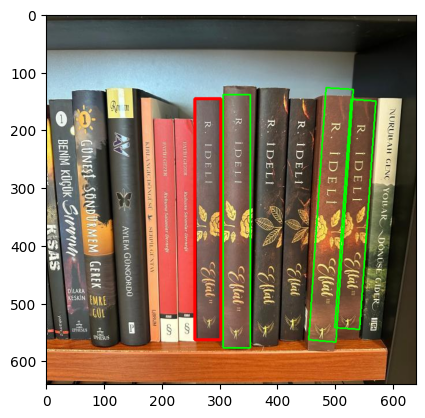

{'book_19-scene_7': {'detections': 4,
  'corners': [array([[[257, 146]],
   
          [[257, 563]],
   
          [[302, 563]],
   
          [[302, 146]]], dtype=int32),
   array([[306, 139],
          [353, 139],
          [353, 577],
          [306, 577]]),
   array([[484, 127],
          [531, 130],
          [501, 567],
          [454, 563]]),
   array([[527, 147],
          [570, 150],
          [542, 545],
          [499, 542]]),
   array([[223, 128],
          [266, 130],
          [252, 525],
          [209, 524]]),
   array([[ 46, 143],
          [ 93, 141],
          [108, 579],
          [ 61, 581]]),
   array([[107, 180],
          [150, 177],
          [178, 572],
          [135, 575]]),
   array([[371, 165],
          [415, 167],
          [401, 573],
          [357, 572]]),
   array([[  9, 146],
          [ 52, 145],
          [ 66, 540],
          [ 23, 542]]),
   array([[176,  11],
          [219,  10],
          [232, 406],
          [189, 407]]),
   array([[568, 24

In [41]:
grayscale = True
lowe_ratio = 0.75
min_match_pct = 0.075
hyst_th = (0.03, 0.33)
# 19-7
# 15-11
# 16-11
# 27-2
# 7-20
scene_path = f'./dataset/scenes/scene_27.jpg'
model_path = f'./dataset/models/model_2.png'

main(model_path, scene_path, 
    grayscale=grayscale, 
    hysteresys_th=hyst_th, 
    min_match_pct=min_match_pct,
    lowe_ratio=lowe_ratio, 
    method=cv2.RANSAC, 
    ransacReprojThreshold=5.0, 
    similarity_measure=cv2.TM_CCOEFF_NORMED,
    book_idx=19,
    scene_idx=7,
    results_dict={},
    visualize=True)

--------------------------------- Processing scene 0 ---------------------------------

 -------- Processing model 0 --------
Book 0 - 0 instance(s) found

 -------- Processing model 1 --------
Book 1 - 0 instance(s) found

 -------- Processing model 2 --------
Book 2 - 0 instance(s) found

 -------- Processing model 3 --------
Book 3 - 0 instance(s) found

 -------- Processing model 4 --------
Book 4 - 0 instance(s) found

 -------- Processing model 5 --------
Book 5 - 0 instance(s) found

 -------- Processing model 6 --------
Book 6 - 0 instance(s) found

 -------- Processing model 7 --------
Book 7 - 0 instance(s) found

 -------- Processing model 8 --------
Book 8 - 0 instance(s) found

 -------- Processing model 9 --------
Book 9 - 0 instance(s) found

 -------- Processing model 10 --------
Book 10 - 0 instance(s) found

 -------- Processing model 11 --------
Book 11 - 0 instance(s) found

 -------- Processing model 12 --------
Book 12 - 0 instance(s) found

 -------- Processing m

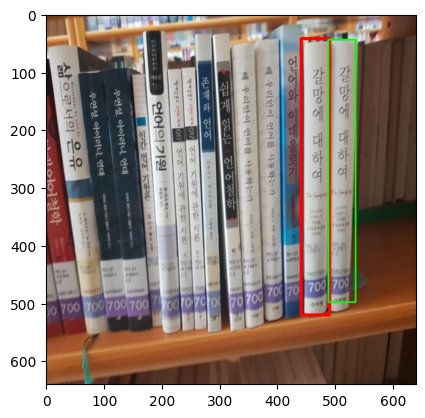

Book 18 - 2 instance(s) found:
	 Instance 1: {top-left: (441, 42), top-right: (490, 42), bottom-left: (441, 520), bottom-right: (490, 520), area: 23422px}
	 Instance 2: {top-left: (322, 84), top-right: (338, 538), bottom-left: (369, 83), bottom-right: (385, 536), area: 21338px}

 -------- Processing model 19 --------
Book 19 - 0 instance(s) found

 -------- Processing model 20 --------
Book 20 - 0 instance(s) found

 -------- Processing model 21 --------
Book 21 - 0 instance(s) found
--------------------------------- Processing scene 2 ---------------------------------

 -------- Processing model 0 --------
Book 0 - 0 instance(s) found

 -------- Processing model 1 --------
Book 1 - 0 instance(s) found

 -------- Processing model 2 --------
Book 2 - 0 instance(s) found

 -------- Processing model 3 --------
Book 3 - 0 instance(s) found

 -------- Processing model 4 --------
Book 4 - 0 instance(s) found

 -------- Processing model 5 --------
Book 5 - 0 instance(s) found

 -------- Proce

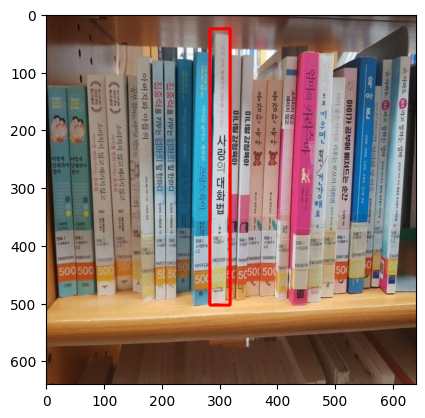

Book 17 - 1 instance(s) found:
	 Instance 1: {top-left: (283, 25), top-right: (318, 25), bottom-left: (283, 503), bottom-right: (318, 503), area: 16730px}

 -------- Processing model 18 --------
Book 18 - 0 instance(s) found

 -------- Processing model 19 --------
Book 19 - 0 instance(s) found

 -------- Processing model 20 --------
Book 20 - 0 instance(s) found

 -------- Processing model 21 --------
Book 21 - 0 instance(s) found
--------------------------------- Processing scene 3 ---------------------------------

 -------- Processing model 0 --------
Book 0 - 0 instance(s) found

 -------- Processing model 1 --------
Book 1 - 0 instance(s) found

 -------- Processing model 2 --------
Book 2 - 0 instance(s) found

 -------- Processing model 3 --------
Book 3 - 0 instance(s) found

 -------- Processing model 4 --------
Book 4 - 0 instance(s) found

 -------- Processing model 5 --------
Book 5 - 0 instance(s) found

 -------- Processing model 6 --------
Book 6 - 0 instance(s) found

 

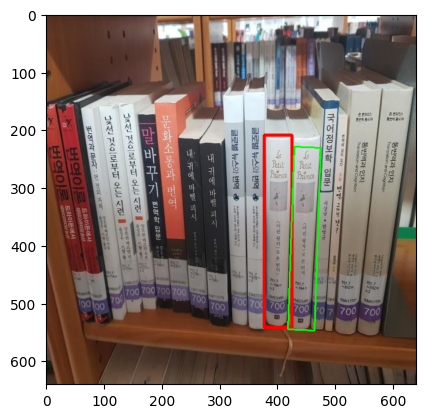

Book 16 - 2 instance(s) found:
	 Instance 1: {top-left: (377, 209), top-right: (425, 209), bottom-left: (377, 542), bottom-right: (425, 542), area: 15984px}
	 Instance 2: {top-left: (429, 229), top-right: (418, 545), bottom-left: (475, 231), bottom-right: (464, 547), area: 14558px}

 -------- Processing model 17 --------
Book 17 - 0 instance(s) found

 -------- Processing model 18 --------
Book 18 - 0 instance(s) found

 -------- Processing model 19 --------
Book 19 - 0 instance(s) found

 -------- Processing model 20 --------
Book 20 - 0 instance(s) found

 -------- Processing model 21 --------
Book 21 - 0 instance(s) found
--------------------------------- Processing scene 4 ---------------------------------

 -------- Processing model 0 --------
Book 0 - 0 instance(s) found

 -------- Processing model 1 --------
Book 1 - 0 instance(s) found

 -------- Processing model 2 --------
Book 2 - 0 instance(s) found

 -------- Processing model 3 --------
Book 3 - 0 instance(s) found

 ------

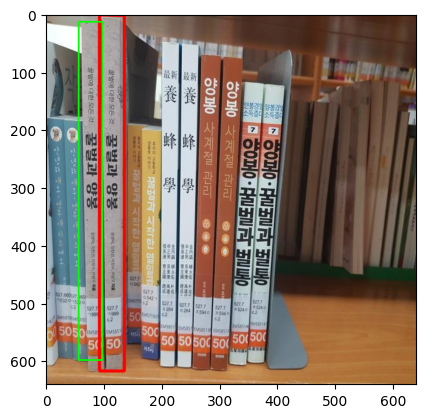

Book 14 - 2 instance(s) found:
	 Instance 1: {top-left: (92, 1), top-right: (135, 2), bottom-left: (92, 617), bottom-right: (135, 617), area: 26466px}
	 Instance 2: {top-left: (56, 13), top-right: (56, 598), bottom-left: (97, 13), bottom-right: (97, 598), area: 23985px}

 -------- Processing model 15 --------
New match found with 333/141 good matches. SSD: 0.13782095909118652.
Not enough matches: 47/143. SSD: 0.15729571878910065.
Not enough matches: 55/146. SSD: 0.17945288121700287.
Not enough matches: 42/152. SSD: 0.23043298721313477.
Not enough matches: 26/155. SSD: 0.25670096278190613.
Not enough matches: 40/157. SSD: 0.27306199073791504.
Not enough matches: 60/160. SSD: 0.29119449853897095.
Not enough matches: 61/163. SSD: 0.3201198875904083.
No match found during template matching on instance 3. Matching value: 0.527807891368866/0.03.


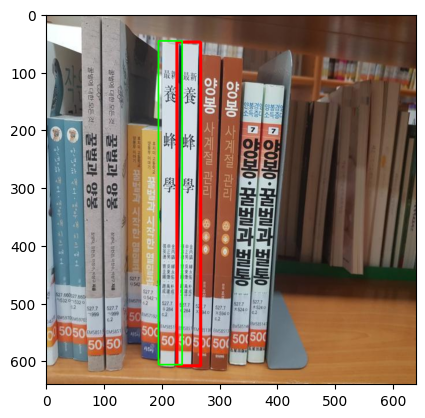

Book 15 - 2 instance(s) found:
	 Instance 1: {top-left: (226, 48), top-right: (267, 48), bottom-left: (226, 608), bottom-right: (267, 608), area: 22960px}
	 Instance 2: {top-left: (194, 46), top-right: (194, 606), bottom-left: (235, 46), bottom-right: (235, 606), area: 22960px}

 -------- Processing model 16 --------
Book 16 - 0 instance(s) found

 -------- Processing model 17 --------
Book 17 - 0 instance(s) found

 -------- Processing model 18 --------
Book 18 - 0 instance(s) found

 -------- Processing model 19 --------
Book 19 - 0 instance(s) found

 -------- Processing model 20 --------
Book 20 - 0 instance(s) found

 -------- Processing model 21 --------
Book 21 - 0 instance(s) found
--------------------------------- Processing scene 5 ---------------------------------

 -------- Processing model 0 --------
Book 0 - 0 instance(s) found

 -------- Processing model 1 --------
Book 1 - 0 instance(s) found

 -------- Processing model 2 --------
Book 2 - 0 instance(s) found

 --------

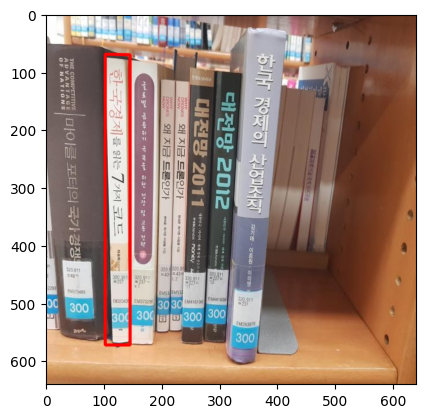

Book 13 - 1 instance(s) found:
	 Instance 1: {top-left: (102, 69), top-right: (145, 70), bottom-left: (102, 572), bottom-right: (145, 572), area: 21607px}

 -------- Processing model 14 --------
Book 14 - 0 instance(s) found

 -------- Processing model 15 --------
Book 15 - 0 instance(s) found

 -------- Processing model 16 --------
Book 16 - 0 instance(s) found

 -------- Processing model 17 --------
Book 17 - 0 instance(s) found

 -------- Processing model 18 --------
Book 18 - 0 instance(s) found

 -------- Processing model 19 --------
Book 19 - 0 instance(s) found

 -------- Processing model 20 --------
Book 20 - 0 instance(s) found

 -------- Processing model 21 --------
Book 21 - 0 instance(s) found
--------------------------------- Processing scene 6 ---------------------------------

 -------- Processing model 0 --------
Book 0 - 0 instance(s) found

 -------- Processing model 1 --------
Book 1 - 0 instance(s) found

 -------- Processing model 2 --------
Book 2 - 0 instance(s) 

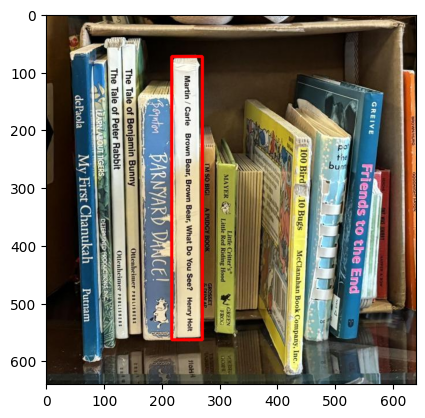

Book 21 - 1 instance(s) found:
	 Instance 1: {top-left: (217, 73), top-right: (270, 73), bottom-left: (217, 563), bottom-right: (270, 563), area: 25970px}
--------------------------------- Processing scene 7 ---------------------------------

 -------- Processing model 0 --------
Book 0 - 0 instance(s) found

 -------- Processing model 1 --------
Book 1 - 0 instance(s) found

 -------- Processing model 2 --------
Book 2 - 0 instance(s) found

 -------- Processing model 3 --------
Book 3 - 0 instance(s) found

 -------- Processing model 4 --------
Book 4 - 0 instance(s) found

 -------- Processing model 5 --------
Book 5 - 0 instance(s) found

 -------- Processing model 6 --------
Book 6 - 0 instance(s) found

 -------- Processing model 7 --------
Book 7 - 0 instance(s) found

 -------- Processing model 8 --------
Book 8 - 0 instance(s) found

 -------- Processing model 9 --------
Book 9 - 0 instance(s) found

 -------- Processing model 10 --------
Book 10 - 0 instance(s) found

 ------

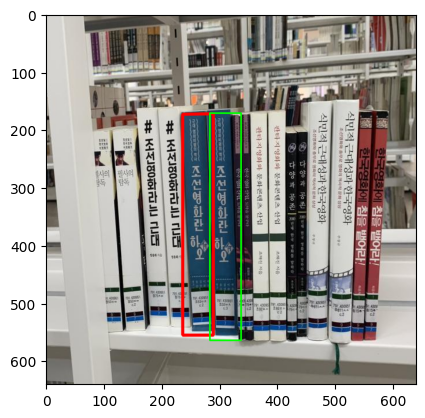

Book 20 - 2 instance(s) found:
	 Instance 1: {top-left: (236, 173), top-right: (289, 172), bottom-left: (236, 555), bottom-right: (289, 555), area: 20272px}
	 Instance 2: {top-left: (283, 171), top-right: (283, 564), bottom-left: (337, 171), bottom-right: (337, 564), area: 21222px}

 -------- Processing model 21 --------
Book 21 - 0 instance(s) found
--------------------------------- Processing scene 8 ---------------------------------

 -------- Processing model 0 --------
Book 0 - 0 instance(s) found

 -------- Processing model 1 --------
Book 1 - 0 instance(s) found

 -------- Processing model 2 --------
Book 2 - 0 instance(s) found

 -------- Processing model 3 --------
Book 3 - 0 instance(s) found

 -------- Processing model 4 --------
Book 4 - 0 instance(s) found

 -------- Processing model 5 --------
Book 5 - 0 instance(s) found

 -------- Processing model 6 --------
Book 6 - 0 instance(s) found

 -------- Processing model 7 --------
Book 7 - 0 instance(s) found

 -------- Proce

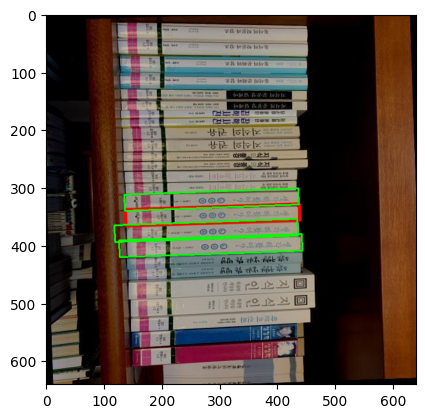

Book 19 - 4 instance(s) found:
	 Instance 1: {top-left: (438, 328), top-right: (439, 356), bottom-left: (137, 338), bottom-right: (138, 366), area: 8438px}
	 Instance 2: {top-left: (135, 312), top-right: (136, 340), bottom-left: (436, 301), bottom-right: (437, 329), area: 8439px}
	 Instance 3: {top-left: (126, 391), top-right: (127, 420), bottom-left: (442, 380), bottom-right: (443, 409), area: 9175px}
	 Instance 4: {top-left: (117, 38), top-right: (116, 65), bottom-left: (410, 48), bottom-right: (409, 75), area: 7921px}

 -------- Processing model 20 --------
Book 20 - 0 instance(s) found

 -------- Processing model 21 --------
Book 21 - 0 instance(s) found
--------------------------------- Processing scene 10 ---------------------------------

 -------- Processing model 0 --------
Book 0 - 0 instance(s) found

 -------- Processing model 1 --------
Book 1 - 0 instance(s) found

 -------- Processing model 2 --------
Book 2 - 0 instance(s) found

 -------- Processing model 3 --------
Bo

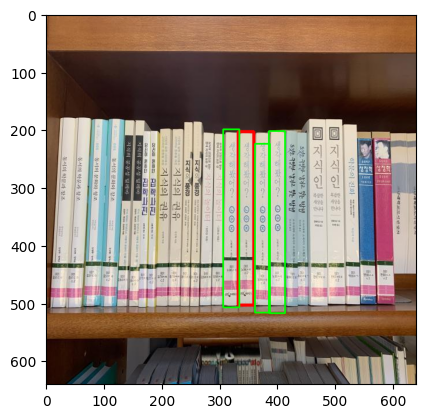

Book 19 - 4 instance(s) found:
	 Instance 1: {top-left: (332, 203), top-right: (359, 203), bottom-left: (332, 503), bottom-right: (359, 503), area: 8100px}
	 Instance 2: {top-left: (306, 199), top-right: (306, 507), bottom-left: (334, 199), bottom-right: (334, 507), area: 8624px}
	 Instance 3: {top-left: (385, 202), top-right: (385, 517), bottom-left: (413, 202), bottom-right: (413, 517), area: 8820px}
	 Instance 4: {top-left: (25, 175), top-right: (15, 467), bottom-left: (51, 176), bottom-right: (41, 468), area: 7602px}

 -------- Processing model 20 --------
Book 20 - 0 instance(s) found

 -------- Processing model 21 --------
Book 21 - 0 instance(s) found
--------------------------------- Processing scene 11 ---------------------------------

 -------- Processing model 0 --------
Book 0 - 0 instance(s) found

 -------- Processing model 1 --------
Book 1 - 0 instance(s) found

 -------- Processing model 2 --------
Book 2 - 0 instance(s) found

 -------- Processing model 3 --------
Bo

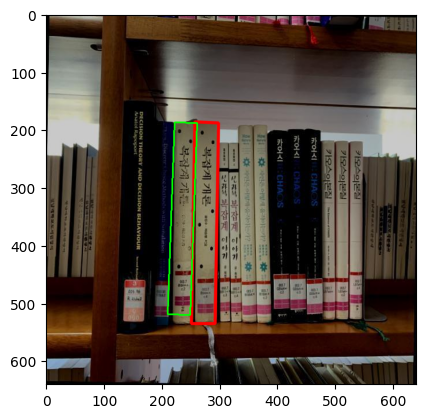

Book 11 - 2 instance(s) found:
	 Instance 1: {top-left: (257, 186), top-right: (298, 188), bottom-left: (251, 535), bottom-right: (292, 535), area: 14274px}
	 Instance 2: {top-left: (332, 204), top-right: (332, 536), bottom-left: (371, 204), bottom-right: (371, 536), area: 12948px}

 -------- Processing model 12 --------
Not enough matches: 11/37. SSD: 0.09704059362411499.
Not enough matches: 4/37. SSD: 0.09844997525215149.
Not enough matches: 9/37. SSD: 0.11657116562128067.
Not enough matches: 9/39. SSD: 0.1630392223596573.
Not enough matches: 8/39. SSD: 0.1673012226819992.
New match found with 62/39 good matches. SSD: 0.17872437834739685.
Not enough matches: 7/40. SSD: 0.2167639136314392.
New match found with 65/41 good matches. SSD: 0.2295757532119751.
Not enough matches: 5/42. SSD: 0.25934815406799316.
Not enough matches: 5/42. SSD: 0.2777846157550812.
Not enough matches: 3/42. SSD: 0.27140894532203674.
Not enough matches: 4/43. SSD: 0.3059085011482239.
Not enough matches: 9/44. SS

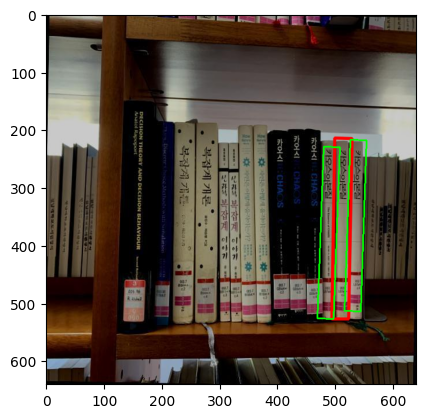

Book 12 - 3 instance(s) found:
	 Instance 1: {top-left: (499, 214), top-right: (529, 215), bottom-left: (494, 527), bottom-right: (523, 527), area: 9221px}
	 Instance 2: {top-left: (331, 157), top-right: (331, 486), bottom-left: (363, 157), bottom-right: (363, 486), area: 10528px}
	 Instance 3: {top-left: (234, 191), top-right: (222, 520), bottom-left: (266, 193), bottom-right: (254, 521), area: 10530px}

 -------- Processing model 13 --------
Book 13 - 0 instance(s) found

 -------- Processing model 14 --------
Book 14 - 0 instance(s) found

 -------- Processing model 15 --------
Book 15 - 0 instance(s) found

 -------- Processing model 16 --------
Book 16 - 0 instance(s) found

 -------- Processing model 17 --------
Book 17 - 0 instance(s) found

 -------- Processing model 18 --------
Book 18 - 0 instance(s) found

 -------- Processing model 19 --------
Book 19 - 0 instance(s) found

 -------- Processing model 20 --------
Book 20 - 0 instance(s) found

 -------- Processing model 21 -

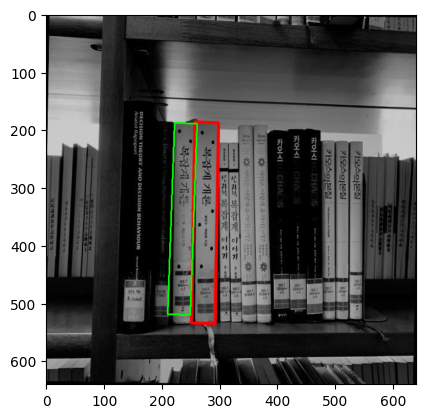

Book 11 - 2 instance(s) found:
	 Instance 1: {top-left: (257, 186), top-right: (298, 188), bottom-left: (251, 534), bottom-right: (292, 535), area: 14256px}
	 Instance 2: {top-left: (332, 205), top-right: (332, 536), bottom-left: (371, 205), bottom-right: (371, 536), area: 12909px}

 -------- Processing model 12 --------
Not enough matches: 11/38. SSD: 0.10201656073331833.
Not enough matches: 8/38. SSD: 0.10644517093896866.
Not enough matches: 13/38. SSD: 0.12069500982761383.
Not enough matches: 13/40. SSD: 0.1674536019563675.
Not enough matches: 8/40. SSD: 0.17409676313400269.
New match found with 67/40 good matches. SSD: 0.18155786395072937.
Not enough matches: 6/42. SSD: 0.22565008699893951.
New match found with 67/42 good matches. SSD: 0.22987329959869385.
Not enough matches: 5/43. SSD: 0.2700595259666443.
Not enough matches: 9/44. SSD: 0.28437942266464233.
Not enough matches: 5/44. SSD: 0.28032809495925903.
Not enough matches: 6/45. SSD: 0.31749141216278076.
Not enough matches: 9/

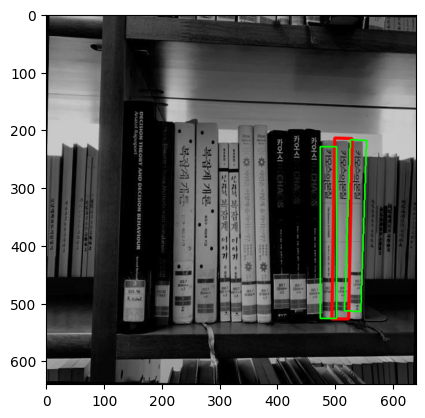

Book 12 - 3 instance(s) found:
	 Instance 1: {top-left: (499, 214), top-right: (529, 215), bottom-left: (494, 527), bottom-right: (523, 527), area: 9221px}
	 Instance 2: {top-left: (234, 191), top-right: (222, 520), bottom-left: (266, 193), bottom-right: (254, 521), area: 10530px}
	 Instance 3: {top-left: (331, 157), top-right: (331, 486), bottom-left: (363, 157), bottom-right: (363, 486), area: 10528px}

 -------- Processing model 13 --------
Book 13 - 0 instance(s) found

 -------- Processing model 14 --------
Book 14 - 0 instance(s) found

 -------- Processing model 15 --------
Book 15 - 0 instance(s) found

 -------- Processing model 16 --------
Book 16 - 0 instance(s) found

 -------- Processing model 17 --------
Book 17 - 0 instance(s) found

 -------- Processing model 18 --------
Book 18 - 0 instance(s) found

 -------- Processing model 19 --------
Book 19 - 0 instance(s) found

 -------- Processing model 20 --------
Book 20 - 0 instance(s) found

 -------- Processing model 21 -

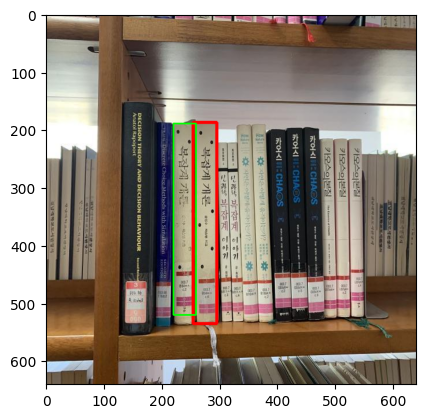

Book 11 - 2 instance(s) found:
	 Instance 1: {top-left: (254, 187), top-right: (295, 187), bottom-left: (254, 535), bottom-right: (295, 535), area: 14268px}
	 Instance 2: {top-left: (325, 204), top-right: (337, 535), bottom-left: (364, 203), bottom-right: (376, 534), area: 12921px}

 -------- Processing model 12 --------
Not enough matches: 13/42. SSD: 0.06069119647145271.
Not enough matches: 11/42. SSD: 0.06466106325387955.
Not enough matches: 12/43. SSD: 0.078023761510849.
Not enough matches: 7/43. SSD: 0.07965400815010071.
New match found with 62/44 good matches. SSD: 0.09897293150424957.
Not enough matches: 12/44. SSD: 0.10271914303302765.
Not enough matches: 12/44. SSD: 0.11714984476566315.
Not enough matches: 13/45. SSD: 0.13259734213352203.
Not enough matches: 12/46. SSD: 0.15461401641368866.
New match found with 52/46 good matches. SSD: 0.15556344389915466.
Not enough matches: 19/46. SSD: 0.16215820610523224.
Not enough matches: 13/46. SSD: 0.16373313963413239.
Not enough match

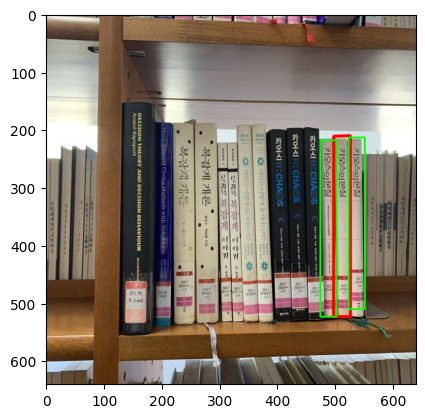

Book 12 - 3 instance(s) found:
	 Instance 1: {top-left: (497, 211), top-right: (526, 210), bottom-left: (497, 523), bottom-right: (526, 523), area: 9062px}
	 Instance 2: {top-left: (232, 173), top-right: (232, 470), bottom-left: (260, 173), bottom-right: (260, 470), area: 8316px}
	 Instance 3: {top-left: (330, 155), top-right: (330, 484), bottom-left: (360, 155), bottom-right: (360, 484), area: 9870px}

 -------- Processing model 13 --------
Book 13 - 0 instance(s) found

 -------- Processing model 14 --------
Book 14 - 0 instance(s) found

 -------- Processing model 15 --------
Book 15 - 0 instance(s) found

 -------- Processing model 16 --------
Book 16 - 0 instance(s) found

 -------- Processing model 17 --------
Book 17 - 0 instance(s) found

 -------- Processing model 18 --------
Book 18 - 0 instance(s) found

 -------- Processing model 19 --------
Book 19 - 0 instance(s) found

 -------- Processing model 20 --------
Book 20 - 0 instance(s) found

 -------- Processing model 21 ---

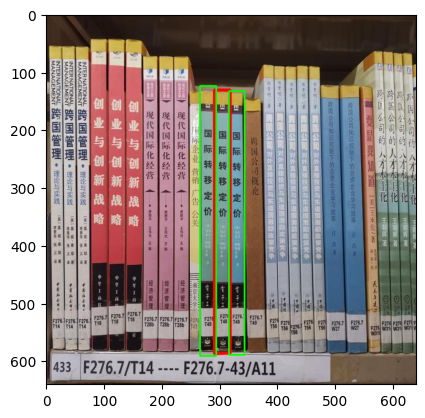

Book 8 - 3 instance(s) found:
	 Instance 1: {top-left: (291, 131), top-right: (318, 131), bottom-left: (291, 587), bottom-right: (318, 586), area: 12298px}
	 Instance 2: {top-left: (316, 133), top-right: (316, 589), bottom-left: (343, 133), bottom-right: (343, 589), area: 12312px}
	 Instance 3: {top-left: (266, 124), top-right: (266, 591), bottom-left: (294, 124), bottom-right: (294, 591), area: 13076px}

 -------- Processing model 9 --------
New match found with 221/84 good matches. SSD: 0.08009979128837585.
New match found with 188/85 good matches. SSD: 0.09336930513381958.
Not enough matches: 33/88. SSD: 0.1343165785074234.
Not enough matches: 30/89. SSD: 0.14680206775665283.
Not enough matches: 45/90. SSD: 0.15391935408115387.
Not enough matches: 36/90. SSD: 0.15533436834812164.
Not enough matches: 41/90. SSD: 0.1562049239873886.
Not enough matches: 44/90. SSD: 0.16043928265571594.
Not enough matches: 30/91. SSD: 0.16542980074882507.
Not enough matches: 46/91. SSD: 0.17065566778182

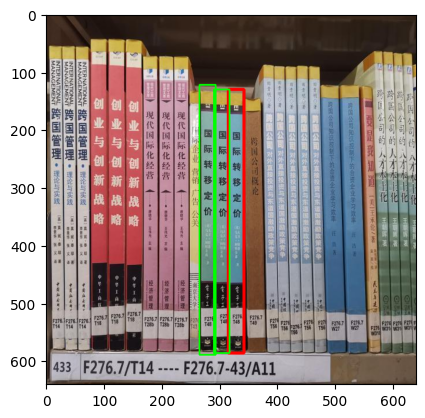

Book 9 - 3 instance(s) found:
	 Instance 1: {top-left: (315, 130), top-right: (342, 130), bottom-left: (315, 586), bottom-right: (342, 586), area: 12312px}
	 Instance 2: {top-left: (290, 130), top-right: (290, 586), bottom-left: (317, 130), bottom-right: (317, 586), area: 12312px}
	 Instance 3: {top-left: (265, 122), top-right: (265, 589), bottom-left: (293, 122), bottom-right: (293, 589), area: 13076px}

 -------- Processing model 10 --------
New match found with 235/74 good matches. SSD: 0.040558408945798874.
Not enough matches: 20/79. SSD: 0.12037337571382523.
Not enough matches: 30/80. SSD: 0.12815114855766296.
Not enough matches: 39/80. SSD: 0.13672283291816711.
Not enough matches: 17/82. SSD: 0.15907786786556244.
Not enough matches: 29/82. SSD: 0.15917646884918213.
Not enough matches: 38/82. SSD: 0.16137318313121796.
Not enough matches: 40/82. SSD: 0.1620466560125351.
Not enough matches: 30/85. SSD: 0.20290572941303253.
Not enough matches: 35/87. SSD: 0.22511537373065948.
Not eno

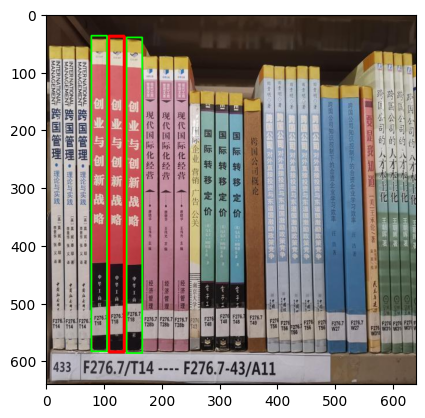

Book 10 - 3 instance(s) found:
	 Instance 1: {top-left: (108, 38), top-right: (135, 38), bottom-left: (108, 584), bottom-right: (135, 584), area: 14742px}
	 Instance 2: {top-left: (78, 37), top-right: (78, 583), bottom-left: (105, 37), bottom-right: (105, 583), area: 14742px}
	 Instance 3: {top-left: (139, 40), top-right: (139, 586), bottom-left: (166, 40), bottom-right: (166, 586), area: 14742px}

 -------- Processing model 11 --------
Book 11 - 0 instance(s) found

 -------- Processing model 12 --------
Book 12 - 0 instance(s) found

 -------- Processing model 13 --------
Book 13 - 0 instance(s) found

 -------- Processing model 14 --------
Book 14 - 0 instance(s) found

 -------- Processing model 15 --------
Book 15 - 0 instance(s) found

 -------- Processing model 16 --------
Book 16 - 0 instance(s) found

 -------- Processing model 17 --------
Book 17 - 0 instance(s) found

 -------- Processing model 18 --------
Book 18 - 0 instance(s) found

 -------- Processing model 19 --------

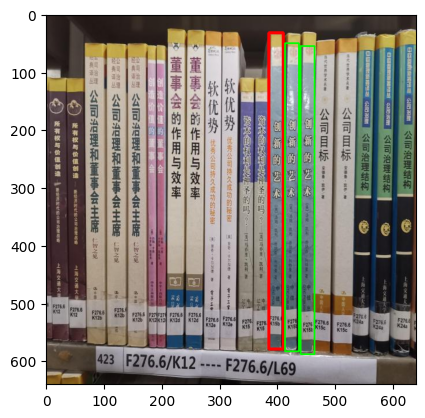

Book 6 - 3 instance(s) found:
	 Instance 1: {top-left: (385, 32), top-right: (410, 32), bottom-left: (385, 579), bottom-right: (410, 579), area: 13675px}
	 Instance 2: {top-left: (413, 50), top-right: (413, 583), bottom-left: (437, 50), bottom-right: (437, 583), area: 12792px}
	 Instance 3: {top-left: (440, 55), top-right: (440, 588), bottom-left: (464, 55), bottom-right: (464, 588), area: 12792px}

 -------- Processing model 7 --------
New match found with 208/64 good matches. SSD: 0.03805122524499893.
Not enough matches: 61/66. SSD: 0.07485771179199219.
Not enough matches: 33/66. SSD: 0.07967522740364075.
Not enough matches: 46/67. SSD: 0.08448243141174316.
Not enough matches: 58/67. SSD: 0.08541476726531982.
Not enough matches: 47/67. SSD: 0.09170077741146088.
Not enough matches: 65/67. SSD: 0.09971838444471359.
Not enough matches: 33/68. SSD: 0.10939474403858185.
Not enough matches: 14/69. SSD: 0.12582452595233917.
Not enough matches: 30/73. SSD: 0.18444199860095978.
Not enough mat

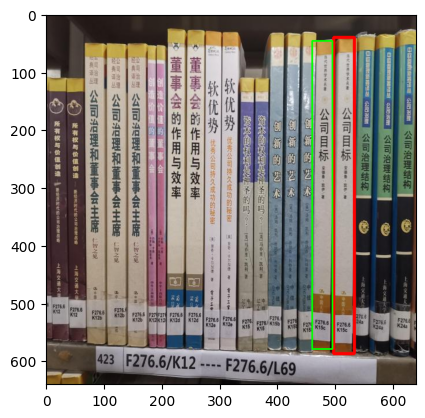

Book 7 - 2 instance(s) found:
	 Instance 1: {top-left: (497, 40), top-right: (533, 40), bottom-left: (497, 587), bottom-right: (533, 587), area: 19692px}
	 Instance 2: {top-left: (460, 46), top-right: (460, 579), bottom-left: (495, 46), bottom-right: (495, 579), area: 18655px}

 -------- Processing model 8 --------
Book 8 - 0 instance(s) found

 -------- Processing model 9 --------
Book 9 - 0 instance(s) found

 -------- Processing model 10 --------
Book 10 - 0 instance(s) found

 -------- Processing model 11 --------
Book 11 - 0 instance(s) found

 -------- Processing model 12 --------
Book 12 - 0 instance(s) found

 -------- Processing model 13 --------
Book 13 - 0 instance(s) found

 -------- Processing model 14 --------
Book 14 - 0 instance(s) found

 -------- Processing model 15 --------
Book 15 - 0 instance(s) found

 -------- Processing model 16 --------
Book 16 - 0 instance(s) found

 -------- Processing model 17 --------
Book 17 - 0 instance(s) found

 -------- Processing mode

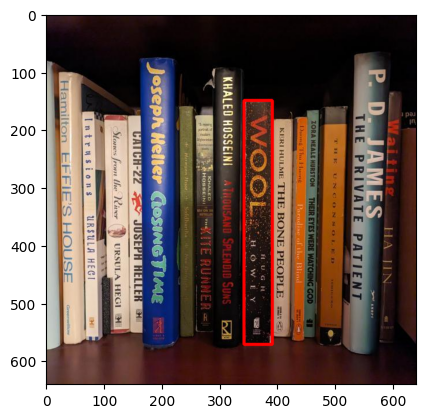

Book 5 - 1 instance(s) found:
	 Instance 1: {top-left: (342, 149), top-right: (391, 149), bottom-left: (342, 571), bottom-right: (391, 571), area: 20678px}

 -------- Processing model 6 --------
Book 6 - 0 instance(s) found

 -------- Processing model 7 --------
Book 7 - 0 instance(s) found

 -------- Processing model 8 --------
Book 8 - 0 instance(s) found

 -------- Processing model 9 --------
Book 9 - 0 instance(s) found

 -------- Processing model 10 --------
Book 10 - 0 instance(s) found

 -------- Processing model 11 --------
Book 11 - 0 instance(s) found

 -------- Processing model 12 --------
Book 12 - 0 instance(s) found

 -------- Processing model 13 --------
Book 13 - 0 instance(s) found

 -------- Processing model 14 --------
Book 14 - 0 instance(s) found

 -------- Processing model 15 --------
Book 15 - 0 instance(s) found

 -------- Processing model 16 --------
Book 16 - 0 instance(s) found

 -------- Processing model 17 --------
Book 17 - 0 instance(s) found

 -------- P

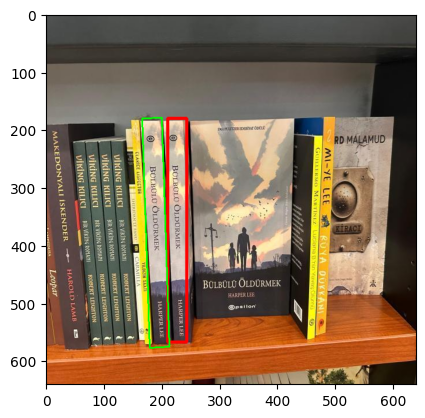

Book 0 - 2 instance(s) found:
	 Instance 1: {top-left: (210, 180), top-right: (243, 180), bottom-left: (210, 567), bottom-right: (243, 567), area: 12771px}
	 Instance 2: {top-left: (166, 180), top-right: (179, 577), bottom-left: (200, 179), bottom-right: (213, 575), area: 13500px}

 -------- Processing model 1 --------
Book 1 - 0 instance(s) found

 -------- Processing model 2 --------
Book 2 - 0 instance(s) found

 -------- Processing model 3 --------
Book 3 - 0 instance(s) found

 -------- Processing model 4 --------
Not enough matches: 100/335. SSD: 0.23706115782260895.
Not enough matches: 88/343. SSD: 0.2654283344745636.
No match found during template matching on instance 2. Matching value: 0.47141575813293457/0.03.


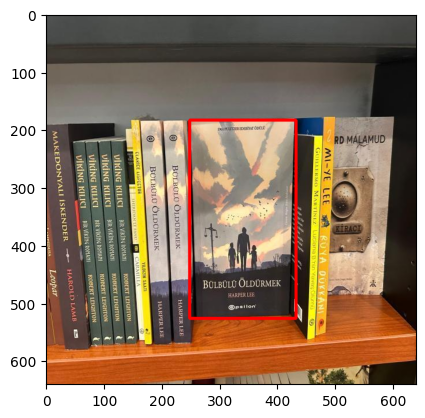

Book 4 - 1 instance(s) found:
	 Instance 1: {top-left: (248, 183), top-right: (432, 183), bottom-left: (248, 526), bottom-right: (432, 526), area: 63112px}

 -------- Processing model 5 --------
Book 5 - 0 instance(s) found

 -------- Processing model 6 --------
Book 6 - 0 instance(s) found

 -------- Processing model 7 --------
Book 7 - 0 instance(s) found

 -------- Processing model 8 --------
Book 8 - 0 instance(s) found

 -------- Processing model 9 --------
Book 9 - 0 instance(s) found

 -------- Processing model 10 --------
Book 10 - 0 instance(s) found

 -------- Processing model 11 --------
Book 11 - 0 instance(s) found

 -------- Processing model 12 --------
Book 12 - 0 instance(s) found

 -------- Processing model 13 --------
Book 13 - 0 instance(s) found

 -------- Processing model 14 --------
Book 14 - 0 instance(s) found

 -------- Processing model 15 --------
Book 15 - 0 instance(s) found

 -------- Processing model 16 --------
Book 16 - 0 instance(s) found

 -------- Pro

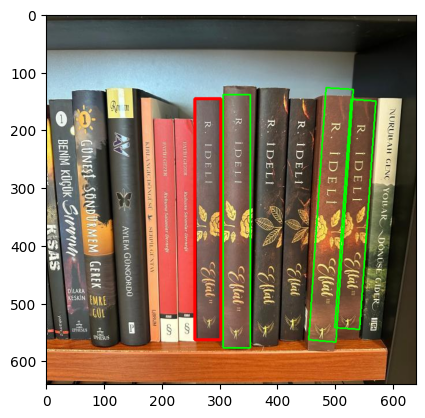

Book 2 - 4 instance(s) found:
	 Instance 1: {top-left: (257, 146), top-right: (302, 146), bottom-left: (257, 563), bottom-right: (302, 563), area: 18765px}
	 Instance 2: {top-left: (306, 139), top-right: (306, 577), bottom-left: (353, 139), bottom-right: (353, 577), area: 20586px}
	 Instance 3: {top-left: (484, 127), top-right: (454, 563), bottom-left: (531, 130), bottom-right: (501, 567), area: 20620px}
	 Instance 4: {top-left: (527, 147), top-right: (499, 542), bottom-left: (570, 150), bottom-right: (542, 545), area: 17069px}

 -------- Processing model 3 --------
New match found with 183/166 good matches. SSD: 0.2099403291940689.
Not enough matches: 42/173. SSD: 0.26436784863471985.
Not enough matches: 118/178. SSD: 0.2997729182243347.
No match found during template matching on instance 3. Matching value: 0.3447478711605072/0.03.


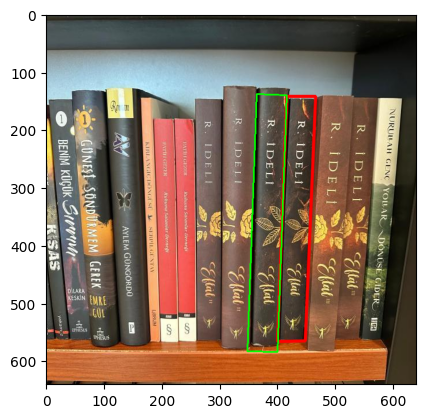

Book 3 - 2 instance(s) found:
	 Instance 1: {top-left: (416, 142), top-right: (466, 142), bottom-left: (400, 566), bottom-right: (448, 565), area: 20743px}
	 Instance 2: {top-left: (364, 138), top-right: (348, 583), bottom-left: (416, 140), bottom-right: (400, 584), area: 23138px}

 -------- Processing model 4 --------
Book 4 - 0 instance(s) found

 -------- Processing model 5 --------
Book 5 - 0 instance(s) found

 -------- Processing model 6 --------
Book 6 - 0 instance(s) found

 -------- Processing model 7 --------
Book 7 - 0 instance(s) found

 -------- Processing model 8 --------
Book 8 - 0 instance(s) found

 -------- Processing model 9 --------
Book 9 - 0 instance(s) found

 -------- Processing model 10 --------
Book 10 - 0 instance(s) found

 -------- Processing model 11 --------
Book 11 - 0 instance(s) found

 -------- Processing model 12 --------
Book 12 - 0 instance(s) found

 -------- Processing model 13 --------
Book 13 - 0 instance(s) found

 -------- Processing model 14

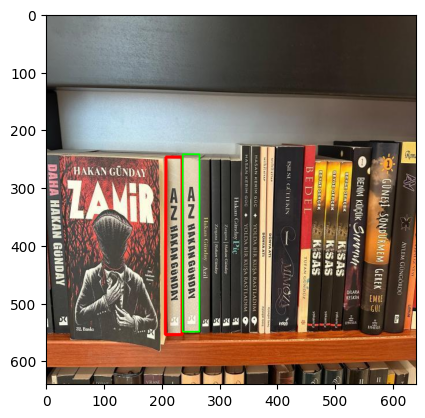

Book 1 - 2 instance(s) found:
	 Instance 1: {top-left: (207, 247), top-right: (235, 247), bottom-left: (206, 554), bottom-right: (235, 554), area: 8749px}
	 Instance 2: {top-left: (236, 242), top-right: (236, 549), bottom-left: (265, 242), bottom-right: (265, 549), area: 8903px}

 -------- Processing model 2 --------
Book 2 - 0 instance(s) found

 -------- Processing model 3 --------
Book 3 - 0 instance(s) found

 -------- Processing model 4 --------
Book 4 - 0 instance(s) found

 -------- Processing model 5 --------
Book 5 - 0 instance(s) found

 -------- Processing model 6 --------
Book 6 - 0 instance(s) found

 -------- Processing model 7 --------
Book 7 - 0 instance(s) found

 -------- Processing model 8 --------
Book 8 - 0 instance(s) found

 -------- Processing model 9 --------
Book 9 - 0 instance(s) found

 -------- Processing model 10 --------
Book 10 - 0 instance(s) found

 -------- Processing model 11 --------
Book 11 - 0 instance(s) found

 -------- Processing model 12 -----

In [47]:
lowe_ratio = 0.75
min_match_pct = 0.075
#hyst_th = (0.465, 0.80)
hyst_th = (0.03, 0.33)

results = {}

for i in range(0, 29):
     print(f"--------------------------------- Processing scene {i} ---------------------------------")
     scene_path = f'./dataset/scenes/scene_{i}.jpg'
     for j in range(0, 22):
          print(f"\n -------- Processing model {j} --------")

          model_path = f'./dataset/models/model_{j}.png'
          
          results = main(model_path, scene_path, 
               hysteresys_th=hyst_th, 
               min_match_pct=min_match_pct,
               lowe_ratio=lowe_ratio, 
               method=cv2.RANSAC, 
               ransacReprojThreshold=5.0, 
               similarity_measure=cv2.TM_CCOEFF_NORMED,
               book_idx=j,
               scene_idx=i,
               results_dict=results,
               visualize=True)
          
          detections = results[f"book_{j}-scene_{i}"]['detections']
          if detections > 0:
               print(f"Book {j} - {detections} instance(s) found:")
               for k in range(detections):
                    corners = results[f"book_{j}-scene_{i}"]['corners'][k]
                    
                    area = results[f"book_{j}-scene_{i}"]['area'][k]

                    top_left     = tuple(map(int, corners[0].ravel()))
                    top_right    = tuple(map(int, corners[3].ravel()))
                    bottom_left  = tuple(map(int, corners[1].ravel()))
                    bottom_right = tuple(map(int, corners[2].ravel()))

                    print(f"\t Instance {k+1}: {{top-left: {top_left}, top-right: {top_right}, bottom-left: {bottom_left}, bottom-right: {bottom_right}, area: {int(area)}px}}")
          else:
               print(f"Book {j} - {detections} instance(s) found")

### **Limitations**

- **Dependence on the First Instance**: The entire pipeline relies on the successful detection of the first instance using SIFT and homography. If the first match fails (e.g., due to occlusion or poor texture), subsequent steps cannot proceed.

(se la prima istanza è occlusa, tutte quelle successive richiedono la stessa occlusione)

- **Limited Robustness to Scale and Rotation Variations**: The method assumes that all book instances appear with similar scale and orientation. While small transformations are handled through rotated and rescaled template matching, larger variations can significantly reduce detection accuracy.

(possimao anche estendere a più angoli e scale ma diventa molto inefficiente)

- **Scalability Constraints**: As the number of model-scene combinations increases, the computational cost grows quickly due to repeated SIFT matching, homography estimation, and iterative template matching, making the approach less suitable for large-scale datasets.
